# NBA East Standings Predictions Tracker

Scores each person's top-10 Eastern Conference predictions against the actual standings, compares two scoring rules, and tracks the leaderboard over the season.

**Data:** run `python fetch_standings.py` for live standings, and put everyone's picks in `data/predictions.csv`. Until those exist, the notebook uses the **made-up** sample files (`make_sample_data.py`), so the numbers below are only a demo.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from score import load_predictions, load_standings, score_predictions, score_full_table

DATA = Path("data")
standings_path = DATA / "east_standings.csv" if (DATA / "east_standings.csv").exists() else DATA / "sample_standings.csv"
predictions_path = DATA / "predictions.csv" if (DATA / "predictions.csv").exists() else DATA / "sample_predictions.csv"
USING_SAMPLE = "sample" in standings_path.name or "sample" in predictions_path.name
print("Standings:  ", standings_path)
print("Predictions:", predictions_path)
if USING_SAMPLE:
    print("\nHeads up: using made-up sample data.")

standings = load_standings(standings_path)
predictions = load_predictions(predictions_path)
standings

Standings:   data/sample_standings.csv
Predictions: data/sample_predictions.csv

Heads up: using made-up sample data.


,rank,team,wins,losses,win_pct
0,1,Charlotte Hornets,15,3,0.833
1,2,New York Knicks,15,3,0.833
2,3,Detroit Pistons,13,5,0.722
3,4,Miami Heat,13,5,0.722
4,5,Boston Celtics,12,6,0.667
5,6,Toronto Raptors,12,6,0.667
6,7,Atlanta Hawks,10,8,0.556
7,8,Indiana Pacers,10,8,0.556
8,9,Chicago Bulls,9,9,0.500
9,10,Philadelphia 76ers,9,9,0.500


## 1. Leaderboard

Each pick's error is the distance between where you ranked a team and where it actually stands. Lowest total wins.

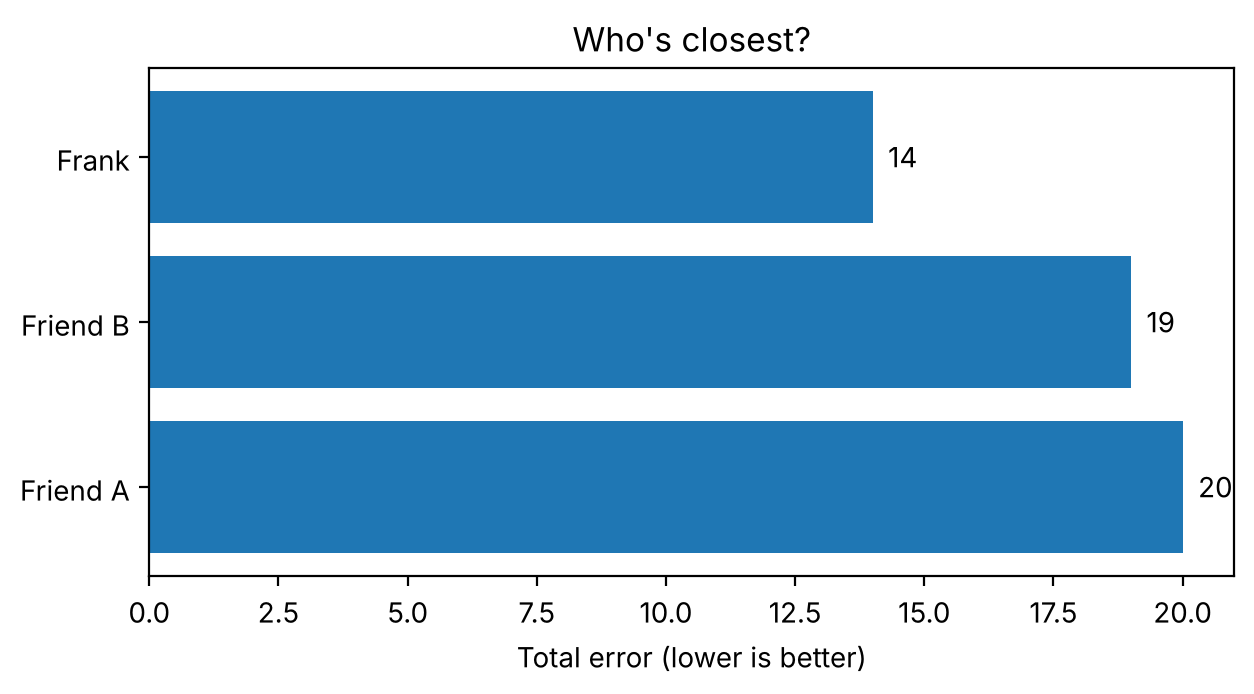

,place,player,total_error,exact_hits,picks
0,1,Frank,14,2,10
1,2,Friend B,19,1,10
2,3,Friend A,20,1,10


In [2]:
detail, leaderboard = score_predictions(predictions, standings, top_n=10)

fig, ax = plt.subplots(figsize=(7, 0.6 * len(leaderboard) + 1.5))
ax.barh(leaderboard["player"], leaderboard["total_error"], color="tab:blue")
ax.invert_yaxis()
ax.set_xlabel("Total error (lower is better)")
ax.set_title("Who's closest?")
for i, v in enumerate(leaderboard["total_error"]):
    ax.text(v + 0.3, i, str(v), va="center")
plt.show()

leaderboard

## 2. Rank correlation

Total error counts how many spots you missed by. Spearman correlation asks a different question: did you get the *order* right? A value of 1 means your 10 picks are in exactly the right order relative to each other.

In [3]:
spearman = (
    detail.groupby("player")
    .apply(lambda d: stats.spearmanr(d["predicted_rank"], d["actual_rank"]).statistic, include_groups=False)
    .rename("spearman")
    .reset_index()
)
comparison = leaderboard[["player", "total_error"]].merge(spearman, on="player")
comparison["rank_by_error"] = comparison["total_error"].rank(method="min").astype(int)
comparison["rank_by_spearman"] = comparison["spearman"].rank(ascending=False, method="min").astype(int)
comparison.round(3)

,player,total_error,spearman,rank_by_error,rank_by_spearman
0,Frank,14,0.830,1,1
1,Friend B,19,0.709,2,3
2,Friend A,20,0.721,3,2


**How to read it:** the two measures usually agree, but they can split. Spearman only looks at the relative order of the 10 teams you picked, so it doesn't care if you picked a team that's actually 13th, as long as it sits in the right order relative to your other picks. Total error does care, because it measures distance from each team's real spot. Total error is the better rule for this contest; Spearman is a useful second look at who read the *shape* of the conference best.

## 3. Which teams did everyone get wrong?

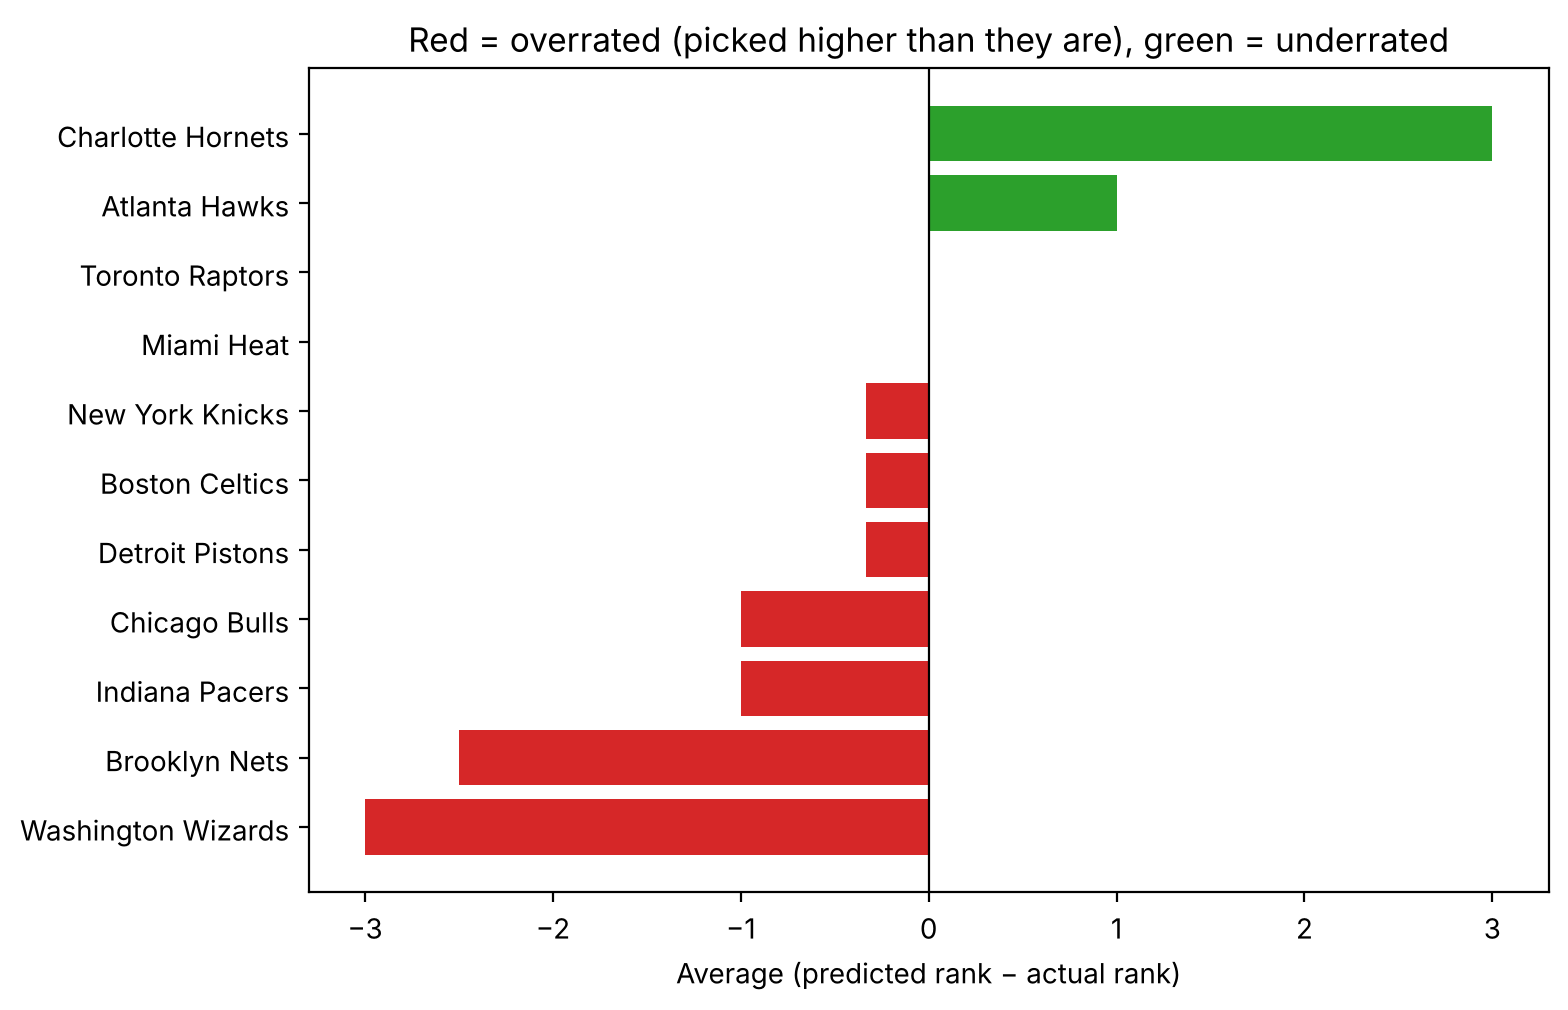

,avg_signed_error,avg_abs_error,times_picked
team,,,
Washington Wizards,-3.00,3.00,1
Brooklyn Nets,-2.50,2.50,2
Indiana Pacers,-1.00,2.33,3
Chicago Bulls,-1.00,1.67,3
Detroit Pistons,-0.33,1.67,3
Boston Celtics,-0.33,1.00,3
New York Knicks,-0.33,1.00,3
Miami Heat,0.00,2.00,3
Toronto Raptors,0.00,1.33,3


In [4]:
detail["signed_error"] = detail["predicted_rank"] - detail["actual_rank"]
by_team = (
    detail.groupby("team")
    .agg(avg_signed_error=("signed_error", "mean"), avg_abs_error=("error", "mean"), times_picked=("error", "size"))
    .sort_values("avg_signed_error")
)

fig, ax = plt.subplots(figsize=(8, 0.35 * len(by_team) + 1.5))
colors = ["tab:red" if v < 0 else "tab:green" for v in by_team["avg_signed_error"]]
ax.barh(by_team.index, by_team["avg_signed_error"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Average (predicted rank − actual rank)")
ax.set_title("Red = overrated (picked higher than they are), green = underrated")
plt.show()

by_team.round(2)

**How to read it:** a negative number means people ranked the team *higher* than it's playing (overrated); positive means *lower* (underrated). `times_picked` matters: a team only one person picked can swing to an extreme average on a single pick.

## 4. Is the scoring rule fair?

The current rule only scores the 10 teams each person picked. That has a blind spot: if you leave out a team that's actually 2nd, you're never penalized for that team directly. You only pay through whichever team you put in its place.

**Alternative rule (full table):** every team counts. A team you didn't pick is treated as if you ranked it 11th ("outside my top 10"), and any team actually outside the top 10 also counts as 11th, so missing the cut by one spot or five costs the same. See `score_full_table` in `score.py`.

In [5]:
full = score_full_table(predictions, standings, top_n=10)
both = leaderboard[["player", "total_error"]].merge(full[["player", "full_table_error"]], on="player")
both["place_current_rule"] = both["total_error"].rank(method="min").astype(int)
both["place_full_table"] = both["full_table_error"].rank(method="min").astype(int)
both.sort_values("place_full_table")

,player,total_error,full_table_error,place_current_rule,place_full_table
0,Frank,14,14,1,1
1,Friend B,19,20,2,2
2,Friend A,20,20,3,2


**Trade-off:** the full-table rule is fairer about leaving out good teams, but it's more lenient about badly wrong picks: putting a team 10th that actually finishes 15th costs 1 point instead of 5. Neither rule is "right"; the group should agree on one before the season. The current rule is simpler to explain, so it stays the official one here, with the full-table rule as a tiebreaker view.

## 5. The leaderboard over the season

Every run of `fetch_standings.py` saves a dated copy in `data/snapshots/`. This scores each snapshot and plots everyone's total error over time.

Using 4 snapshots from data/sample_snapshots (made up)


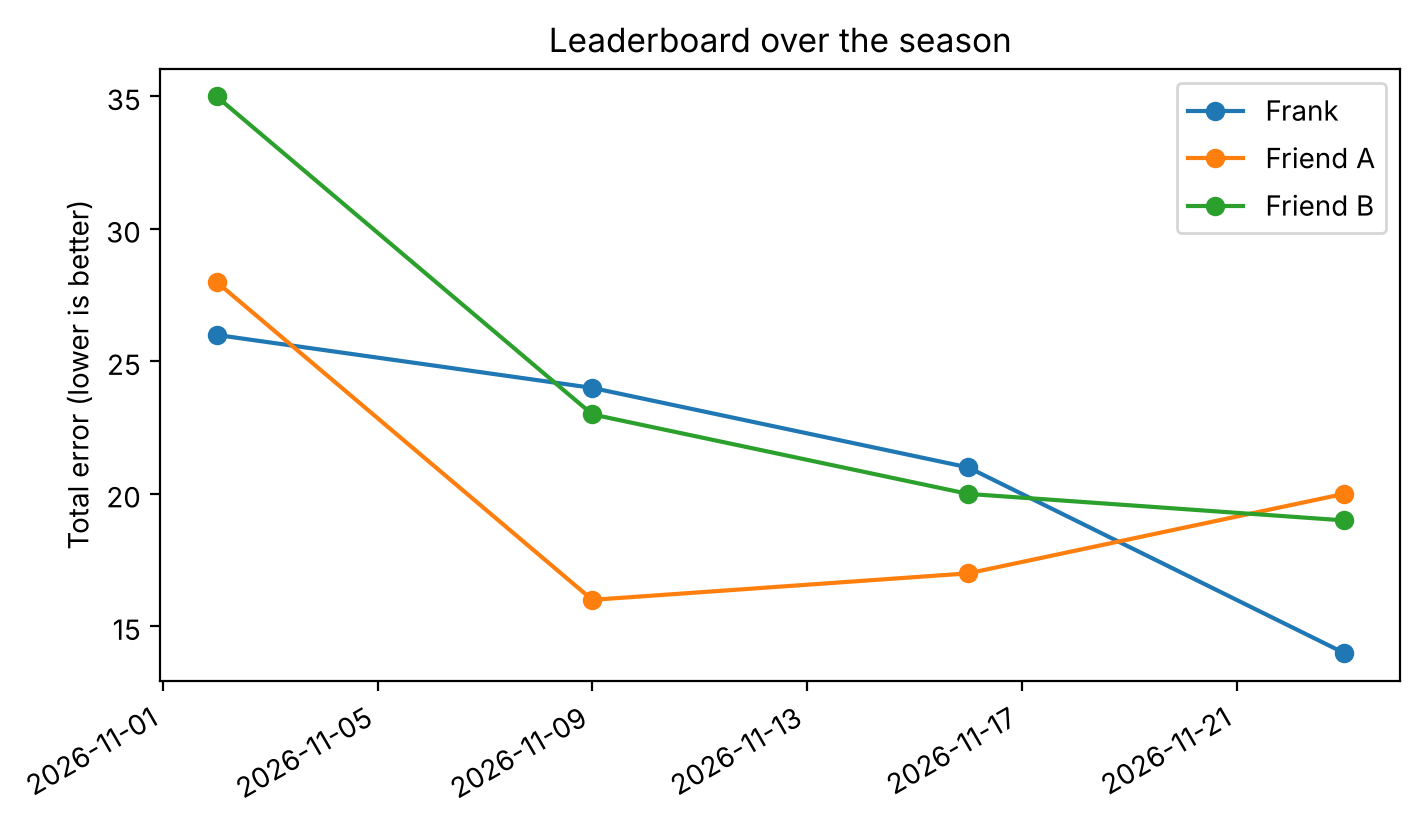

player,Frank,Friend A,Friend B
date,,,
2026-11-02,26,28,35
2026-11-09,24,16,23
2026-11-16,21,17,20
2026-11-23,14,20,19


In [6]:
real_snaps = sorted((DATA / "snapshots").glob("east_standings_*.csv"))
snaps = real_snaps if len(real_snaps) >= 2 else sorted((DATA / "sample_snapshots").glob("east_standings_*.csv"))
print(f"Using {len(snaps)} snapshots from", snaps[0].parent if snaps else "nowhere", "(made up)" if snaps and snaps[0].parent.name == "sample_snapshots" else "")

history = []
for path in snaps:
    snap_date = pd.to_datetime(path.stem.replace("east_standings_", ""))
    _, board = score_predictions(predictions, load_standings(path), top_n=10)
    history.append(board.assign(date=snap_date))
history = pd.concat(history, ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
for player, d in history.groupby("player"):
    ax.plot(d["date"], d["total_error"], marker="o", label=player)
ax.set_ylabel("Total error (lower is better)")
ax.set_title("Leaderboard over the season")
ax.legend()
fig.autofmt_xdate()
plt.show()

history.pivot(index="date", columns="player", values="total_error")

## Takeaways

- **Two scores, two questions.** Total error measures how far off each pick is; Spearman measures whether the order was right. Showing both makes the leaderboard harder to argue with.
- **The scoring rule changes the winner more than you'd think.** Scoring only your own picks ignores good teams you left out; scoring the full table fixes that but goes easy on picks that badly miss. Agree on the rule before the season.
- **Snapshots turn a one-off check into a season-long story.** Running the fetch script weekly builds a history you can chart with no extra work.